# 02 - Convolutional VAE + k-means or GMM

Learns a 16-dimensional summary of each daily scalogram (128 scales x 24 hours). K-means or a Gaussian mixture on those summaries plus the daily price level assigns each day to a market regime.

Pipeline: scalogram -> ConvVAE encoder -> latent mean (mu) + daily price level -> k-means or GMM -> regime

Methodology notes:
1. Days are split chronologically (60% train, 20% validation, 20% test). The 2023-2024 El Nino falls in the test period.
2. The clustering is fitted on training days only and then applied to all days.
3. Scalograms come from the real price with each day's mean removed, so they show only the intraday shape. `real_price_log` uses the log real price and `real_price` the real price in COP/kWh. The daily level (mean and standard deviation of the same series) is added to the latent vector before clustering.
4. The VAE is trained once (or loaded with `load_from`). The clustering then runs once for each k in `k_values`, and each k gets its own run folder in `experiments/conv_vae/<clustering>/<study>/` and its own row in `experiments/registry.csv`. `trained_in` in each config names the run where the model was trained, so runs with the same `trained_in` share the same latents.

<d.benavidess@uniandes.edu.co>

In [1]:
import sys
sys.path.append("..")

from pathlib import Path

import torch

import numpy as np
import pandas as pd
import altair as alt
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader

plt.rcParams['font.family'] = 'Arial'
alt.data_transformers.enable('vegafusion')

from src.data import load_scalograms, load_context, chronological_split, ScalogramDataset
from src.models.conv_vae import ConvVAE
from src.training import set_seed, train
from src.clustering import with_level, level_columns, select_k, active_dims
from src.plots import loss_curves, selection_chart, plot_reconstructions
from src.runs import prepare_runs, save_all, cluster_runs, k_sweep_table, tsne_grid, regime_strips
from src import experiments as exp

In [2]:
import warnings
warnings.filterwarnings("ignore")

## 0. Experiment configuration

Change only this cell between runs.
- `scalogram_set` is `"real_price_log"` or `"real_price"`.
- `clustering` is `"kmeans"`. A GMM (`"gmm"`) was tested and discarded: with these latents k-means wins in separation, persistence and El Nino capture (runs in `experiments/conv_vae/gmm/clustering/`). The option is kept to compare again if the latents change.
- `k_values` is the list of k. The model is trained once and each k gets its own run folder.
- `study` names the question the run answers, and is saved in `config.json` and `registry.csv` so the registry can be filtered by it: `"k_sweep"` (choose k), `"price_set"` (log vs linear price), `"clustering"` (k-means vs GMM), `"vae_model"` (ConvVAE vs Temporal VAE) or `"hyperparameters"`.
- `tag` is an optional short label added at the end of the run folder name, e.g. `"z4"`, to tell apart runs of the same study. Leave it empty to omit it.
- `load_from` is the `run_id` of an earlier run, e.g. `"conv_vae/kmeans/k_sweep/001_real_price_log_kmeans_k2"`. When set, training is skipped and that run's model, history and latents are reused. Its set and hyperparameters are used too, so only `clustering`, `k_values`, `k_range`, `study` and `tag` come from this cell. Use it to try other k or the other clustering algorithm on the same latents.

In [3]:
scalogram_set = "real_price_log"
clustering = "kmeans"
k_values = [2, 3, 4, 5, 6]
study = "k_sweep"
tag = ""
load_from = None

config = {
    "model": "conv_vae",
    "study": study,
    "tag": tag,
    "scalogram_set": scalogram_set,
    "clustering": clustering,
    "k_values": k_values,
    "k_range": [2, 3, 4, 5, 6, 7, 8],
    "z_dim": 16,
    "filters": [128, 64, 32],
    "beta": 1.0,
    "kl_warmup_epochs": 0,
    "optimizer": "Adam",
    "lr": 1e-3,
    "batch_size": 64,
    "epochs": 30,
    "train_ratio": 0.6,
    "val_ratio": 0.2,
    "seed": 42,
}

## 1. Run folders

One folder per k, created before training.

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
config, run_dirs, run_configs, trained = prepare_runs(config, load_from, device)
set_seed(config["seed"])

for k, run_dir in run_dirs.items():
    print(f"k={k}: {exp.run_id(run_dir)}")
print(f"Model: {'loaded from ' + load_from if trained else 'trained in this notebook'}")
print(f"trained_in: {run_configs[config['k_values'][0]]['trained_in']}")
print(f"Device: {device}")

k=2: conv_vae/gmm/006_real_price_gmm_k2
k=3: conv_vae/gmm/007_real_price_gmm_k3
k=4: conv_vae/gmm/008_real_price_gmm_k4
k=5: conv_vae/gmm/009_real_price_gmm_k5
k=6: conv_vae/gmm/010_real_price_gmm_k6
Model: loaded from conv_vae/kmeans/006_real_price_kmeans_k2
trained_in: conv_vae/kmeans/006_real_price_kmeans_k2
Device: cpu


## 2. Data

In [5]:
scalogram_dir = Path("../data/processed/scalograms") / config["scalogram_set"]
data_dir = Path("../data/processed")

images, metadata = load_scalograms(scalogram_dir)
context = load_context(data_dir, metadata)
train_idx, val_idx, test_idx = chronological_split(len(images), config["train_ratio"], config["val_ratio"])
split_dates = [context["date"].iloc[val_idx[0]], context["date"].iloc[test_idx[0]]]

img_c, img_h, img_w = images.shape[1:]
print(f"Scalograms ({config['scalogram_set']}): {images.shape}, range [{images.min():.3f}, {images.max():.3f}]")
print(f"Daily level columns: {level_columns(metadata)}")
splits = exp.split_table(context, {"train": train_idx, "val": val_idx, "test": test_idx})
print(splits)

Scalograms (real_price): (9709, 1, 128, 24), range [0.000, 1.000]
Daily level columns: ('price_mean', 'price_std')
+-------+------+------------+------------+
| Split | Days |    From    |     To     |
+-------+------+------------+------------+
| train | 5825 | 2000-01-01 | 2015-12-12 |
|  val  | 1942 | 2015-12-13 | 2021-04-06 |
|  test | 1942 | 2021-04-07 | 2026-07-31 |
+-------+------+------------+------------+


In [6]:
train_loader = DataLoader(ScalogramDataset(images, train_idx), batch_size=config["batch_size"], shuffle=True)
val_loader = DataLoader(ScalogramDataset(images, val_idx), batch_size=config["batch_size"], shuffle=False)

In [7]:
def bce_floor(x):
    x = np.clip(x.reshape(len(x), -1).astype(np.float64), 1e-7, 1 - 1e-7)
    return -(x * np.log(x) + (1 - x) * np.log(1 - x)).sum(axis=1)

for name, idx in (("train", train_idx), ("val", val_idx), ("test", test_idx)):
    f = bce_floor(images[idx])
    print(f"{name}: floor {f.mean():.0f}, mean pixel {images[idx].mean():.3f}")

train: floor 664, mean pixel 0.075
val: floor 776, mean pixel 0.097
test: floor 879, mean pixel 0.156


## 3. Model

In [8]:
model = ConvVAE(config["z_dim"], img_c, img_h, img_w, config["filters"]).to(device)
if trained:
    model.load_state_dict(trained["state_dict"])

with torch.no_grad():
    out_shape = tuple(model(torch.from_numpy(images[:2]).to(device))[0].shape[1:])
assert out_shape == (img_c, img_h, img_w), f"decoder output {out_shape} does not match input"
print(f"Encoder feature map: {model.encoder.feat_shape}")
print(f"Decoder output: {out_shape}")

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
hyperparameters = exp.hyperparameter_table(config, n_params)
print(hyperparameters)
save_all(run_dirs, exp.save_table, "hyperparameters", hyperparameters, show=False)

Encoder feature map: (32, 16, 3)
Decoder output: (1, 128, 24)
+----------------------------+-----------------+
| Hyperparameter             |      Value      |
+----------------------------+-----------------+
| Latent dimension           |        16       |
| Encoder filters            | 128 -> 64 -> 32 |
| Decoder filters            | 32 -> 64 -> 128 |
| Beta (KL weight)           |       1.0       |
| Smoothness weight (lambda) |        -        |
| KL warm-up epochs          |        0        |
| Optimizer, learning rate   |   Adam, 0.001   |
| Batch size                 |        64       |
| Epochs                     |        30       |
| Trainable parameters       |     263,169     |
+----------------------------+-----------------+


## 4. Training

Skipped when `load_from` is set. The history and weights then come from that run.

In [9]:
if trained:
    history = trained["history"]
    print(f"Training skipped. History loaded from {load_from} ({len(history)} epochs).")
else:
    history = train(model, train_loader, val_loader, device, epochs=config["epochs"], lr=config["lr"],
                    beta=config["beta"], kl_warmup_epochs=config["kl_warmup_epochs"])
save_all(run_dirs, exp.save_history, history)
save_all(run_dirs, exp.save_model, model)

Training skipped. History loaded from conv_vae/kmeans/006_real_price_kmeans_k2 (30 epochs).


## 5. Loss curves

In [10]:
loss_plot = loss_curves(history, components=("total", "recon", "kl"))
for run_dir in run_dirs.values():
    loss_plot.save(exp.figure_path(run_dir, "loss_curves"), scale_factor=2.0)
loss_plot

alt.HConcatChart(...)

## 6. Reconstructions

Test-period days.

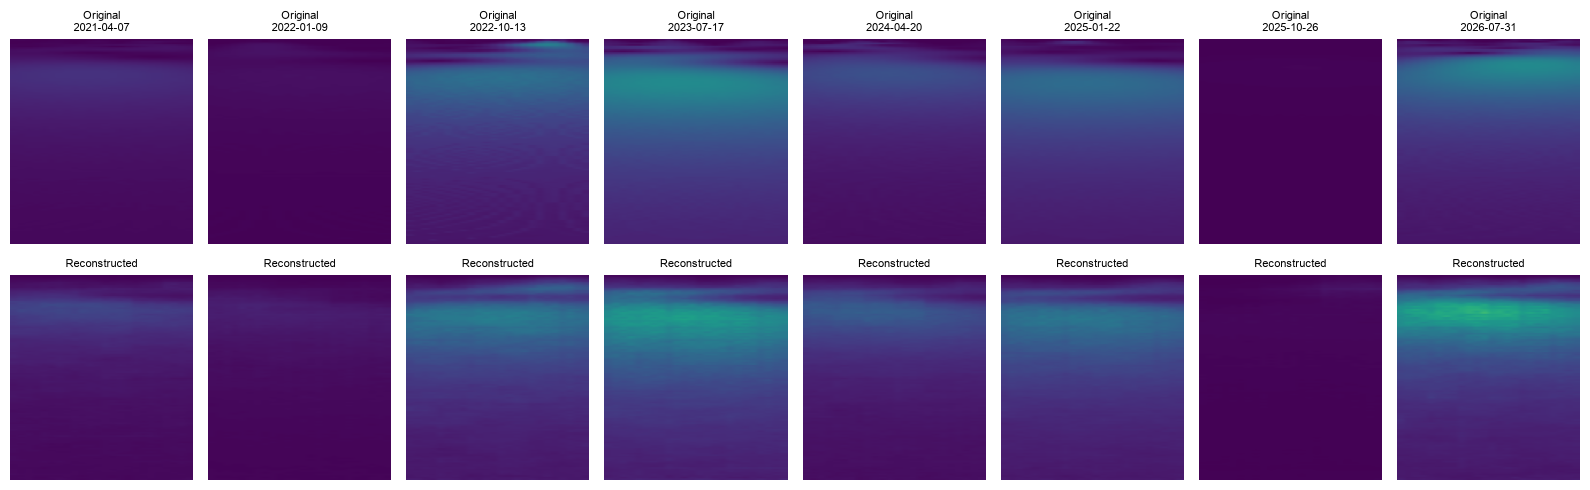

In [11]:
model.eval()
show_idx = test_idx[np.linspace(0, len(test_idx) - 1, 8).astype(int)]
with torch.no_grad():
    recon = model(torch.from_numpy(images[show_idx]).to(device))[0].cpu().numpy()

fig = plot_reconstructions(images[show_idx], recon, [str(d.date()) for d in context["date"].iloc[show_idx]])
for run_dir in run_dirs.values():
    fig.savefig(exp.figure_path(run_dir, "reconstructions"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Latent vectors

In [12]:
latents = trained["latents"] if trained else model.extract_latents(images, device)
save_all(run_dirs, exp.save_latents, latents)
features = with_level(latents, metadata, train_idx)

active = active_dims(latents)
print(f"Latent vectors: {latents.shape}")
print(f"Final train KL: {history[-1]['train_kl']:.2f}")
print(f"Active dimensions (variance > 0.1): {active} of {config['z_dim']}")
print(f"Clustering features (latents + daily level): {features.shape}")
print("Latent variance per dim:", np.round(latents.var(axis=0), 5))

Latent vectors: (9709, 16)
Final train KL: 4.46
Active dimensions: 15 of 16
Clustering features (latents + daily level): (9709, 18)
Latent variance per dim: [0.74315 0.08646 0.17351 0.35629 0.21191 0.14703 0.58905 0.03712 0.05036
 0.01468 0.02239 0.07384 0.08148 2.99305 0.05509 0.0095 ]


## 8. Choice of k

Clustering uses the latent vector plus the daily price level (mean and standard deviation, z-scored on training days), because the scalograms only carry the intraday shape. It is fitted on the training days only and then assigns every day. Regimes are numbered by ascending mean real price, so regime 0 is always the cheapest and labels are comparable across models.

The table is the same for every k in `k_values`, so it is computed once. For each k on the training days it shows the inertia (k-means, look for the elbow) or the BIC (GMM, lower is better), silhouette (higher is better), Davies-Bouldin (lower is better) and Calinski-Harabasz (higher is better). These only measure separation. Persistence and the regime profiles are in section 10.

In [13]:
selection = select_k(features, train_idx, config["clustering"], config["k_range"], config["seed"])
selection_table = exp.selection_table(selection)
print(selection_table)
save_all(run_dirs, exp.save_table, "k_selection", selection_table, show=False)
selection_chart(selection, config["k_values"][0])

+---+----------+------------+----------------+-------------------+
| k |   BIC    | Silhouette | Davies-Bouldin | Calinski-Harabasz |
+---+----------+------------+----------------+-------------------+
| 2 | -231,191 |   0.339    |     1.334      |       2,092       |
| 3 | -266,390 |   0.291    |     1.996      |       1,436       |
| 4 | -285,966 |   0.209    |     2.015      |       1,206       |
| 5 | -292,011 |   0.208    |     1.869      |       1,303       |
| 6 | -295,433 |   0.196    |     2.014      |       1,198       |
| 7 | -299,318 |   0.207    |     1.563      |       1,369       |
| 8 | -304,007 |   0.238    |     1.511      |       1,359       |
+---+----------+------------+----------------+-------------------+


alt.HConcatChart(...)

## 9. One run per k

The t-SNE map depends only on the features, so it is computed once and colored with each k's regimes. For each k, `cluster_runs` saves to its run folder:
- figures: k selection, t-SNE, regime timeline (the loss curves and reconstructions are saved above)
- tables: regime profile, clustering metrics, price spread by regime, share of each weekday in each regime, and the feature checks below
- `regimes.csv` with one row per day: split, regime, real price, ONI, `nino` (1 if ONI >= 0.5), `episode` (2015-2016, 2023-2024 or empty), `top_regime` (1 in the most expensive regime) and `captured` (1 if an El Nino day fell in the most expensive regime), plus the GMM probabilities. `python scripts/inspect_regimes.py <run>` summarizes it.
- `metrics.json` and its row in `registry.csv`

In [14]:
rng = np.random.default_rng(config["seed"])
plot_idx = np.sort(rng.choice(len(features), size=min(5000, len(features)), replace=False))
coords = TSNE(n_components=2, perplexity=30, random_state=config["seed"]).fit_transform(features[plot_idx])

smooth = pd.DataFrame(latents).rolling(7, min_periods=1).mean().to_numpy()
feature_sets = {
    "level only": with_level(np.zeros((len(latents), 0)), metadata, train_idx),
    "latents only": latents,
    "latents + level": features,
    "7d-mean latents + level": with_level(smooth, metadata, train_idx),
}
results = cluster_runs(run_dirs, run_configs, features, context, train_idx, split_dates, selection,
                       coords, plot_idx, feature_sets)

k=2: conv_vae/gmm/006_real_price_gmm_k2  silhouette=0.310  mean run=4.2 d  switches/yr=86.7
k=3: conv_vae/gmm/007_real_price_gmm_k3  silhouette=0.253  mean run=3.1 d  switches/yr=117.4
k=4: conv_vae/gmm/008_real_price_gmm_k4  silhouette=0.172  mean run=2.4 d  switches/yr=153.3
k=5: conv_vae/gmm/009_real_price_gmm_k5  silhouette=0.164  mean run=2.1 d  switches/yr=171.6
k=6: conv_vae/gmm/010_real_price_gmm_k6  silhouette=0.148  mean run=2.0 d  switches/yr=180.0


In [15]:
tsne_grid(coords, plot_idx, results)

alt.VConcatChart(...)

## 10. Comparison across k

One row per k. The top regime is the most expensive one (highest number). The last two columns are the share of El Nino days (ONI >= 0.5) in 2015-2016 and in 2023-2024 that fall in the top regime. Read them against `top_share_pct`: if the top regime holds 70% of all days, holding 70% of El Nino days says nothing. A regime that tracks scarcity holds a much larger share of El Nino days than of all days, and switches few times per year.

In [16]:
k_sweep = k_sweep_table(results)
save_all(run_dirs, exp.save_table, "k_sweep", k_sweep, show=False)
k_sweep

,silhouette,davies_bouldin,calinski_harabasz,mean_run_days,switches_per_year,top_share_pct,top_price,top_reservoir,nino_2015_16_in_top_pct,nino_2023_24_in_top_pct
k,,,,,,,,,,
2,0.310,1.294,3365.439,4.210,86.713,44.176,407.152,0.668,64.797,76.418
3,0.253,1.730,2442.992,3.109,117.449,17.654,629.390,0.650,45.455,66.866
4,0.172,1.910,1904.202,2.382,153.300,13.266,707.143,0.649,39.845,60.000
5,0.164,2.149,2019.616,2.128,171.621,8.487,717.154,0.636,24.178,36.119
6,0.148,2.010,1985.776,2.029,179.973,0.793,1445.415,0.610,5.416,3.284


In [17]:
for k, r in results.items():
    print(f"k={k}  {exp.run_id(run_dirs[k])}")
    print(exp.regime_profile_table(r["profile"]))
    print("Share of each weekday in each regime (%)")
    print(r["weekday"].to_string(), end="\n\n")

k=2  conv_vae/gmm/006_real_price_gmm_k2
+--------+------+---------+------------+-----------+----------+-----------+
| Regime | Days | Share % | Real price | Reservoir | Mean ONI | El Nino % |
+--------+------+---------+------------+-----------+----------+-----------+
|   0    | 5420 |   55.8  |   244.0    |   0.687   |  -0.06   |    21.1   |
|   1    | 4289 |   44.2  |   407.2    |   0.668   |   0.09   |    29.4   |
+--------+------+---------+------------+-----------+----------+-----------+
Share of each weekday in each regime (%)
         Mon   Tue   Wed   Thu   Fri   Sat   Sun
regime                                          
0       52.0  49.0  49.0  52.0  56.0  64.0  68.0
1       48.0  51.0  51.0  48.0  44.0  36.0  32.0

k=3  conv_vae/gmm/007_real_price_gmm_k3
+--------+------+---------+------------+-----------+----------+-----------+
| Regime | Days | Share % | Real price | Reservoir | Mean ONI | El Nino % |
+--------+------+---------+------------+-----------+----------+-----------

Regime strip for every k, one row per k.

In [18]:
regime_strips(results)

alt.VConcatChart(...)